# Week 11 Contest: Round 2

**Open this notebook when your instructor tells you to.**

The factory has had a busy few weeks. You now have two new files:

- `round2_train.csv.gz`: **newly labelled** rows from the period right after your original training data
- `test_final.csv.gz`: the rows you'll be scored on from now on. They come after `round2_train` in time.

Everything else about the contest is unchanged: same columns, same metric, 5 submissions, public leaderboard on
30% and private final score on 70%.

Your Round 1 model will probably not do as well as it did. Your job in this round is to work out **why** and fix
it. Open the data and compare it with the old data. Answer these before touching a model:

1. Do the columns in `round2_train` look like the columns in `train`? Which ones are different?
2. Is the failure rate the same?
3. Are there new kinds of rows? (Think about Week 10.)
4. How should you validate now? What should your validation set look like?

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import f1_score, classification_report

GROUP_NAME = "Tyler-Mrgaj"
# Full path so it works no matter which folder the kernel starts in (the folder name has a space in it)
DATA_DIR = "/Users/tylerkatz/Documents/IST-707/IST707-Notebooks/week11/round 2/data"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
round2 = pd.read_csv(f"{DATA_DIR}/round2_train.csv")
test_final = pd.read_csv(f"{DATA_DIR}/test_final.csv")
features = [c for c in train.columns if c.startswith("f")]

print("train:", train.shape, "  round2_train:", round2.shape, "  test_final:", test_final.shape)
print("failure rate  train: %.3f   round2: %.3f" % (train["label"].mean(), round2["label"].mean()))

In [ ]:
import os, re
from datetime import datetime

def make_submission(test_df, preds, group, round_name, out_dir="my_submissions"):
    """Validate predictions and write  <group>__<round>__<HHMMSS>.csv  ready to hand in."""
    preds = np.asarray(preds).astype(int)
    assert len(preds) == len(test_df), f"Expected {len(test_df)} predictions, got {len(preds)}"
    assert set(np.unique(preds)) <= {0, 1}, "Predictions must be hard 0/1 labels, not probabilities"
    group = re.sub(r"[^A-Za-z0-9]+", "-", group).strip("-")
    os.makedirs(out_dir, exist_ok=True)
    path = f"{out_dir}/{group}__{round_name}__{datetime.now():%H%M%S}.csv"
    pd.DataFrame({"id": test_df["id"].values, "pred": preds}).to_csv(path, index=False)
    print(f"Wrote {path}  ({preds.mean():.1%} predicted positive)")
    return path

## Compare the two periods

Start here, then keep going on your own.

In [ ]:
comp = pd.DataFrame({
    "train_mean": train[features].mean(),
    "round2_mean": round2[features].mean(),
    "train_std": train[features].std(),
    "round2_std": round2[features].std(),
})
comp["mean_shift_in_std"] = (comp["round2_mean"] - comp["train_mean"]) / comp["train_std"]
comp.reindex(comp["mean_shift_in_std"].abs().sort_values(ascending=False).index).head(10).round(3)

## Your turn

Build your best model for `test_final`, then submit with:

```python
make_submission(test_final, preds, GROUP_NAME, "final")
```

## Before the debrief, write down (a few sentences each)

1. What exactly was different in Round 2 and how did you find it?
2. What did your Round 1 model get wrong because of it?
3. What did you change, and what did that change to your validation score?
4. What did you try that **didn't** help?
5. If this were a real factory, what would you tell the operations manager to check?

fit rows: 380,000 (train 300,000 + round2 80,000)   validation rows: 40,000
failure rate  fit: 0.064   validation: 0.083

1) Round 1 model (train only)     @ 0.27: 0.7294   best 0.7342 @ 0.21
2) Retrained on train + round2    best 0.7594 @ 0.31
Fitting 1 folds for each of 12 candidates, totalling 12 fits
                                                         params  mean_test_score
{'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 10}         0.760859
{'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 30}         0.760465
{'learning_rate': 0.05, 'max_depth': 4, 'min_child_weight': 10}         0.759471
{'learning_rate': 0.03, 'max_depth': 5, 'min_child_weight': 10}         0.759434
{'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 10}         0.759392
{'learning_rate': 0.03, 'max_depth': 6, 'min_child_weight': 30}         0.759329
Best params: {'learning_rate': 0.03, 'max_depth': 4, 'min_child_weight': 10}

Validation macro F1 (last 40k round2 rows)
  Roun

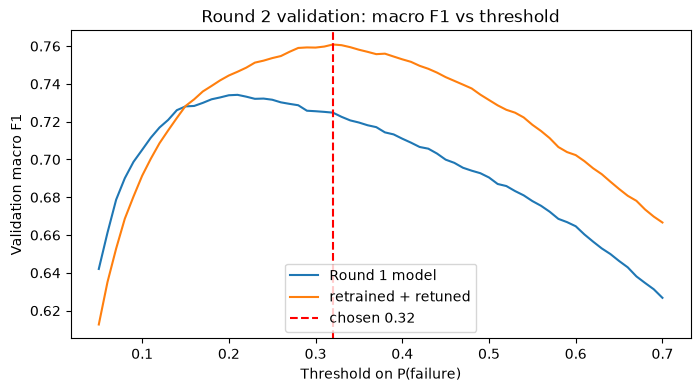

test_final predicted failures: 7.3%   (validation predicted 7.1%, actual 8.3%)
Wrote my_submissions/Tyler-Mrgaj__final__190010.csv  (7.3% predicted positive)


'my_submissions/Tyler-Mrgaj__final__190010.csv'

In [8]:
# --- Round 2: retrain + retune XGBoost on Round 1 + Round 2 data ---
# Validation: the LAST 40k round2 rows (ids 480k-520k). They are closest in time to test_final, and an
# adversarial check showed round2 and test_final are nearly indistinguishable (AUC 0.53), so this is our best
# stand-in for the test set. Models train on all original rows + the FIRST 80k round2 rows.
# Final model: retrain on everything (original train + all 120k round2 rows) and submit.
# Runtime: about 3-5 minutes (the grid search is 12 fits on ~380k rows).
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import GridSearchCV, PredefinedSplit

# ---- Features (same as Round 1) ----
F12_SHIFT_ID = 150_000   # f12 jumps from ~133 to ~310 here; every round2/test_final row is in the "after" period

def f12_stats(df):
    """Median and IQR of f12 before and after the shift, learned from training rows only."""
    stats = {}
    for name, part in [("before", df[df["id"] < F12_SHIFT_ID]), ("after", df[df["id"] >= F12_SHIFT_ID])]:
        v = part["f12"]
        stats[name] = (v.median(), v.quantile(0.75) - v.quantile(0.25))
    return stats

def prepare_features(df, stats):
    """f12 standardised within its period + the f15 x f20 interaction (failures ~14% when signs agree, ~2.5% when not)."""
    X = df[features].copy()
    for name, mask in [("before", df["id"] < F12_SHIFT_ID), ("after", df["id"] >= F12_SHIFT_ID)]:
        med, iqr = stats[name]
        X.loc[mask, "f12"] = (X.loc[mask, "f12"] - med) / iqr
    X["f15_x_f20"] = df["f15"] * df["f20"]
    both_present = df["f15"].notna() & df["f20"].notna()
    X["f15_f20_same_sign"] = (np.sign(df["f15"]) == np.sign(df["f20"])).astype(float).where(both_present)
    return X

thresholds = np.arange(0.05, 0.71, 0.01)

def sweep(y_true, proba):
    """Macro F1 at every threshold -> (best F1, best threshold, all F1s)."""
    f1s = np.array([f1_score(y_true, (proba >= t).astype(int), average="macro") for t in thresholds])
    return f1s.max(), thresholds[f1s.argmax()], f1s

# ---- Time-based split ----
r2_fit, r2_val = round2.iloc[:80_000], round2.iloc[80_000:]
fit_df = pd.concat([train, r2_fit], ignore_index=True)
stats_fit = f12_stats(fit_df)
X_fit, y_fit = prepare_features(fit_df, stats_fit), fit_df["label"].values
X_val, y_val = prepare_features(r2_val, stats_fit), r2_val["label"].values
print(f"fit rows: {len(fit_df):,} (train {len(train):,} + round2 {len(r2_fit):,})   validation rows: {len(r2_val):,}")
print(f"failure rate  fit: {y_fit.mean():.3f}   validation: {y_val.mean():.3f}\n")

ROUND1_SETTINGS = dict(n_estimators=1000, learning_rate=0.03, max_depth=5, min_child_weight=10,
                       subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0)

# 1) Round 1 model as it was: original train only, Round 1 cut-off 0.27
r1_model = XGBClassifier(**ROUND1_SETTINGS).fit(prepare_features(train, stats_fit), train["label"])
r1_proba = r1_model.predict_proba(X_val)[:, 1]
r1_best, r1_t, _ = sweep(y_val, r1_proba)
print(f"1) Round 1 model (train only)     @ 0.27: {f1_score(y_val, (r1_proba >= 0.27).astype(int), average='macro'):.4f}"
      f"   best {r1_best:.4f} @ {r1_t:.2f}")

# 2) Same settings, retrained on train + round2 (untuned)
untuned = XGBClassifier(**ROUND1_SETTINGS).fit(X_fit, y_fit)
untuned_best, untuned_t, _ = sweep(y_val, untuned.predict_proba(X_val)[:, 1])
print(f"2) Retrained on train + round2    best {untuned_best:.4f} @ {untuned_t:.2f}")

# 3) Retune on the same split. Scorer = macro F1 at the best threshold, because the right cut-off moved
#    (failure rate went from 5.8% to 8.4%) and differs between settings.
def best_threshold_macro_f1(estimator, X, y):
    return sweep(y, estimator.predict_proba(X)[:, 1])[0]

split = PredefinedSplit(np.r_[np.full(len(X_fit), -1), np.zeros(len(X_val), dtype=int)])
grid = GridSearchCV(
    XGBClassifier(n_estimators=1000, subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=0),
    {"max_depth": [4, 5, 6], "min_child_weight": [10, 30], "learning_rate": [0.03, 0.05]},
    scoring=best_threshold_macro_f1, cv=split, refit=False, verbose=1,
)
grid.fit(pd.concat([X_fit, X_val]), np.r_[y_fit, y_val])
grid_results = pd.DataFrame(grid.cv_results_)[["params", "mean_test_score"]].sort_values("mean_test_score", ascending=False)
print(grid_results.head(6).to_string(index=False))
print("Best params:", grid.best_params_)

TUNED_SETTINGS = {**ROUND1_SETTINGS, **grid.best_params_}
tuned = XGBClassifier(**TUNED_SETTINGS).fit(X_fit, y_fit)
tuned_proba = tuned.predict_proba(X_val)[:, 1]
tuned_best, final_threshold, tuned_f1s = sweep(y_val, tuned_proba)
tuned_pred = (tuned_proba >= final_threshold).astype(int)

print(f"\nValidation macro F1 (last 40k round2 rows)")
print(f"  Round 1 model, old cut-off 0.27      : {f1_score(y_val, (r1_proba >= 0.27).astype(int), average='macro'):.4f}")
print(f"  Round 1 model, retuned cut-off {r1_t:.2f} : {r1_best:.4f}")
print(f"  Retrained on train + round2          : {untuned_best:.4f} @ {untuned_t:.2f}")
print(f"  Retrained + retuned                  : {tuned_best:.4f} @ {final_threshold:.2f}")
print(classification_report(y_val, tuned_pred, digits=3))
print(confusion_matrix(y_val, tuned_pred))

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(thresholds, sweep(y_val, r1_proba)[2], label="Round 1 model")
ax.plot(thresholds, tuned_f1s, label="retrained + retuned")
ax.axvline(final_threshold, color="red", linestyle="--", label=f"chosen {final_threshold:.2f}")
ax.set_xlabel("Threshold on P(failure)"); ax.set_ylabel("Validation macro F1")
ax.set_title("Round 2 validation: macro F1 vs threshold"); ax.legend(); plt.show()

# 4) Final model: retrain on ALL labelled rows (train + all 120k round2) and write the submission
full_df = pd.concat([train, round2], ignore_index=True)
stats_full = f12_stats(full_df)
final_model = XGBClassifier(**TUNED_SETTINGS).fit(prepare_features(full_df, stats_full), full_df["label"])
test_proba = final_model.predict_proba(prepare_features(test_final, stats_full))[:, 1]
preds = (test_proba >= final_threshold).astype(int)
print(f"test_final predicted failures: {preds.mean():.1%}   (validation predicted {tuned_pred.mean():.1%}, actual {y_val.mean():.1%})")
make_submission(test_final, preds, GROUP_NAME, "final")